# Component 3 — Cross-Year Semantic Harmonization

This notebook converts the separate staged fisheries artifacts into one canonical schema using evidence-based assumptions. It preserves every staged record in an all-records artifact and creates a stricter modelling-candidate view. It does not calculate CPUE or join environmental data.

## Adopted assumptions

1. `kg` and `weight` represent catch weight in kilograms.
2. `qty` and `amount` represent a count-like quantity, not weight.
3. A row represents a species catch line within a fishing event or trip.
4. Fishing/set date fields are preferred over departure or arrival dates.
5. Latitude/longitude fields follow their source labels; ambiguous compact numeric encodings are flagged but not guessed.
6. Model candidates must fall inside the provisional Western Province coastal window within the common environmental coverage.
7. The 2022 issue sheet remains available in the all-records artifact but is excluded from modelling candidates.
8. Exact duplicates across canonical analytical fields are excluded only from the modelling-candidate view.
9. Comparable effort is unavailable across years, so the provisional target is catch weight rather than CPUE.

In [8]:
import importlib.util, subprocess, sys
packages = {'pandas':'pandas>=2.0,<3','numpy':'numpy>=1.24,<3','pyarrow':'pyarrow>=14,<22','matplotlib':'matplotlib>=3.7,<4'}
missing = [spec for module, spec in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
print('Harmonization dependencies are available.')


Harmonization dependencies are available.


In [9]:
from __future__ import annotations
import gc, json, os, re, sys
from pathlib import Path
import matplotlib
if 'IPython' not in sys.modules:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    display = print
pd.set_option('display.max_columns', 60)


## 1. Configure Colab or local paths

In [10]:
def find_component_root(start: Path) -> Path:
    for anchor in [start.resolve(), *start.resolve().parents]:
        for candidate in [anchor, anchor/'component - 3', anchor/'J26-DS-350'/'component - 3']:
            if (candidate/'Notebooks').is_dir() and (candidate/'src').is_dir(): return candidate.resolve()
    raise FileNotFoundError('Component 3 repository root was not found.')

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/FishGuard-C3')
    INTERIM_DIR = ROOT/'data'/'interim'
    PROCESSED_DIR = ROOT/'data'/'processed'
    EVIDENCE_DIR = ROOT/'outputs'/'audit'/'harmonization'
    FIGURE_DIR = ROOT/'outputs'/'figures'/'harmonization'
else:
    COMPONENT_ROOT = find_component_root(Path.cwd())
    INTERIM_DIR = Path(os.getenv('FISHGUARD_C3_INTERIM_INPUT', str(COMPONENT_ROOT/'data'/'interim'))).resolve()
    PROCESSED_DIR = Path(os.getenv('FISHGUARD_C3_PROCESSED_OUTPUT', str(COMPONENT_ROOT/'data'/'processed'))).resolve()
    EVIDENCE_DIR = Path(os.getenv('FISHGUARD_C3_HARMONIZATION_OUTPUT', str(COMPONENT_ROOT/'outputs'/'audit'/'harmonization'))).resolve()
    FIGURE_DIR = Path(os.getenv('FISHGUARD_C3_HARMONIZATION_FIGURES', str(COMPONENT_ROOT/'outputs'/'figures'/'harmonization'))).resolve()
for directory in [PROCESSED_DIR,EVIDENCE_DIR,FIGURE_DIR]: directory.mkdir(parents=True,exist_ok=True)
# Provisional Western Province coastal window, clipped to the common audited environmental grids.
# This is an operational rectangular filter, not an official administrative-boundary polygon.
STUDY_BOUNDS={'latitude_min':6.30,'latitude_max':6.979164,'longitude_min':79.270844,'longitude_max':80.30}
print('Runtime:', 'Google Colab' if IN_COLAB else 'Local Windows')
print('Interim input:', INTERIM_DIR)
print('Western Province study bounds:', STUDY_BOUNDS)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Runtime: Google Colab
Interim input: /content/drive/MyDrive/FishGuard-C3/data/interim
Western Province study bounds: {'latitude_min': 6.3, 'latitude_max': 6.979164, 'longitude_min': 79.270844, 'longitude_max': 80.3}


## 2. Year-specific semantic mapping

In [11]:
MAPPINGS = [
 {'year':2017,'file':'fisheries_2017_staged.parquet','species':'catch','weight':'kg','quantity':'qty','vessel':'reg_num','gear':'gear','date_mode':'ymd','month':'unnamed_2','day':'unnamed_3','lat':'latti','lon':'longi'},
 {'year':2018,'file':'fisheries_2018_staged.parquet','species':'fish_name','weight':'kg','quantity':'amount','vessel':'boat_no','gear':'catch_type','date_mode':'ymd_fields','year_field':'y','month':'m','day':'d','lat':'lat','lon':'long'},
 {'year':2019,'file':'fisheries_2019_staged.parquet','species':'fish_name','weight':'kg','quantity':'amount','vessel':'boat_no','gear':'catch_type','date_mode':'ymd','month':'month','day':'date_of_set','lat':'latitude','lon':'longetude'},
 {'year':2020,'file':'fisheries_2020_staged.parquet','species':'name','weight':'weight','quantity':'qty','vessel':'vessel_id','gear':'geartype','date_mode':'field','date':'dateandtime','lat':'latttitude','lon':'longitude','direction':'gps_derection'},
 {'year':2021,'file':'fisheries_2021_staged.parquet','species':'name','weight':'weight','quantity':'qty','vessel':'vessel_id','gear':'geartype','date_mode':'field','date':'date_time','lat':'start_n','lon':'start_e','direction':'startgpsderec'},
 {'year':2022,'file':'fisheries_2022_staged.parquet','species':'name','weight':'weight','quantity':'qty','vessel':'vessel_id','gear':'geartype','date_mode':'field','date':'date_time','lat':'lattude','lon':'longitude','direction':'lattude_direction'},
 {'year':2022,'file':'fisheries_2022_issues.parquet','species':'name','weight':'weight','quantity':'qty','vessel':'vessel_id','gear':'geartype','date_mode':'field','date':'date_time','lat':'lattitude','lon':'longitude','direction':'lattude_direction'},
 {'year':2023,'file':'fisheries_2023_staged.parquet','species':'name','weight':'weight','quantity':'qty','vessel':'vessel_id','gear':'geartype','date_mode':'field','date':'date_time','lat':'start_n','lon':'start_e'},
 {'year':2024,'file':'fisheries_2024_staged.parquet','species':'name','weight':'weight','quantity':'qty','vessel':'vessel_id','gear':'geartype','date_mode':'field','date':'date_time','lat':'start_n','lon':'start_e','direction':'startgpsderec'},
]
display(pd.DataFrame(MAPPINGS))


,year,file,species,weight,quantity,vessel,gear,date_mode,month,day,lat,lon,year_field,date,direction
0,2017,fisheries_2017_staged.parquet,catch,kg,qty,reg_num,gear,ymd,unnamed_2,unnamed_3,latti,longi,NaN,NaN,NaN
1,2018,fisheries_2018_staged.parquet,fish_name,kg,amount,boat_no,catch_type,ymd_fields,m,d,lat,long,y,NaN,NaN
2,2019,fisheries_2019_staged.parquet,fish_name,kg,amount,boat_no,catch_type,ymd,month,date_of_set,latitude,longetude,NaN,NaN,NaN
3,2020,fisheries_2020_staged.parquet,name,weight,qty,vessel_id,geartype,field,NaN,NaN,latttitude,longitude,NaN,dateandtime,gps_derection
4,2021,fisheries_2021_staged.parquet,name,weight,qty,vessel_id,geartype,field,NaN,NaN,start_n,start_e,NaN,date_time,startgpsderec
5,2022,fisheries_2022_staged.parquet,name,weight,qty,vessel_id,geartype,field,NaN,NaN,lattude,longitude,NaN,date_time,lattude_direction
6,2022,fisheries_2022_issues.parquet,name,weight,qty,vessel_id,geartype,field,NaN,NaN,lattitude,longitude,NaN,date_time,lattude_direction
7,2023,fisheries_2023_staged.parquet,name,weight,qty,vessel_id,geartype,field,NaN,NaN,start_n,start_e,NaN,date_time,NaN
8,2024,fisheries_2024_staged.parquet,name,weight,qty,vessel_id,geartype,field,NaN,NaN,start_n,start_e,NaN,date_time,startgpsderec


## 3. Parsing and harmonization functions

In [12]:
def text(series): return series.astype('string').str.strip().str.replace(r'\s+',' ',regex=True)
def numeric(series): return pd.to_numeric(series,errors='coerce')

def coordinate(series):
    raw=text(series); direct=pd.to_numeric(raw,errors='coerce')
    pattern=raw.str.extract(r'(?i)^\s*([NSEW])?\s*(\d{1,3})(?:[^0-9]+(\d+(?:\.\d+)?))?')
    degrees=pd.to_numeric(pattern[1],errors='coerce'); minutes=pd.to_numeric(pattern[2],errors='coerce').fillna(0)
    parsed=degrees+minutes/60; hemisphere=pattern[0].str.upper()
    parsed=parsed.where(~hemisphere.isin(['S','W']),-parsed)
    return direct.fillna(parsed)

def apply_latitude_direction(latitude,direction):
    if direction is None: return latitude
    d=text(direction).str.lower(); absolute=latitude.abs()
    return latitude.where(~d.str.startswith('s',na=False),-absolute).where(~d.str.startswith('n',na=False),absolute)

def event_date(frame,mapping):
    if mapping['date_mode']=='field': return pd.to_datetime(frame[mapping['date']],errors='coerce',dayfirst=True,format='mixed')
    year=numeric(frame[mapping['year_field']]) if mapping['date_mode']=='ymd_fields' else pd.Series(mapping['year'],index=frame.index)
    components=pd.DataFrame({'year':year,'month':numeric(frame[mapping['month']]),'day':numeric(frame[mapping['day']])},index=frame.index)
    # Convert pandas nullable integers to floats so missing components become NaN instead of raising during assembly.
    components=components.apply(pd.to_numeric,errors='coerce').astype('float64')
    return pd.to_datetime(components,errors='coerce')

def harmonize(frame,mapping):
    out=pd.DataFrame(index=frame.index)
    for field in ['source_year_label','source_file','source_sheet','source_role','source_row_number']:
        out[field]=frame[field]
    out['species']=text(frame[mapping['species']]).str.lower()
    out['catch_weight_kg']=numeric(frame[mapping['weight']])
    out['quantity_count_candidate']=numeric(frame[mapping['quantity']])
    out['vessel_id']=text(frame[mapping['vessel']]).str.upper()
    out['gear']=text(frame[mapping['gear']]).str.lower()
    out['event_date']=event_date(frame,mapping)
    raw_latitude=numeric(frame[mapping['lat']]); raw_longitude=numeric(frame[mapping['lon']])
    out['latitude']=coordinate(frame[mapping['lat']])
    out['longitude']=coordinate(frame[mapping['lon']])
    if mapping.get('direction'): out['latitude']=apply_latitude_direction(out['latitude'],frame[mapping['direction']])
    out['date_valid']=out['event_date'].between(pd.Timestamp('2017-01-01'),pd.Timestamp('2024-12-31'))
    out['coordinates_valid']=out['latitude'].between(-90,90)&out['longitude'].between(-180,180)
    out['ambiguous_encoded_coordinate']=raw_latitude.abs().gt(90)|raw_longitude.abs().gt(180)
    out['in_study_area']=out['latitude'].between(STUDY_BOUNDS['latitude_min'],STUDY_BOUNDS['latitude_max'])&out['longitude'].between(STUDY_BOUNDS['longitude_min'],STUDY_BOUNDS['longitude_max'])
    out['weight_valid']=out['catch_weight_kg'].notna()&(out['catch_weight_kg']>=0)
    out['species_valid']=out['species'].notna()&out['species'].ne('')
    key=['source_year_label','vessel_id','event_date','latitude','longitude','gear']
    complete=out[key].notna().all(axis=1)
    out['event_id']=pd.Series(pd.NA,index=out.index,dtype='string')
    out.loc[complete,'event_id']='EVT-'+pd.util.hash_pandas_object(out.loc[complete,key],index=False).astype(str)
    return out


## 4. Harmonize and combine staged artifacts

In [13]:
parts=[]; source_summary=[]
for mapping in MAPPINGS:
    path=INTERIM_DIR/mapping['file']
    if not path.is_file(): raise FileNotFoundError(f'Missing staged input: {path}. Run 02_data_cleaning.ipynb first.')
    staged=pd.read_parquet(path); canonical=harmonize(staged,mapping)
    parts.append(canonical)
    source_summary.append({'year':mapping['year'],'file':mapping['file'],'rows':len(canonical),
        'valid_dates':int(canonical.date_valid.sum()),'valid_coordinates':int(canonical.coordinates_valid.sum()),
        'study_area_rows':int(canonical.in_study_area.sum()),'ambiguous_encoded_coordinates':int(canonical.ambiguous_encoded_coordinate.sum()),
        'valid_weights':int(canonical.weight_valid.sum()),'valid_species':int(canonical.species_valid.sum()),
        'latitude_min':canonical.latitude.min(),'latitude_max':canonical.latitude.max(),
        'longitude_min':canonical.longitude.min(),'longitude_max':canonical.longitude.max()})
    del staged,canonical; gc.collect()
all_records=pd.concat(parts,ignore_index=True); del parts; gc.collect()
duplicate_key=['source_year_label','vessel_id','event_date','latitude','longitude','gear','species','catch_weight_kg','quantity_count_candidate']
all_records['exact_canonical_duplicate']=all_records.duplicated(duplicate_key,keep='first')
all_records['core_fields_valid']=all_records[['date_valid','coordinates_valid','weight_valid','species_valid']].all(axis=1)
all_records['model_candidate']=all_records.core_fields_valid & all_records.in_study_area & all_records.source_role.eq('candidate_observations') & ~all_records.exact_canonical_duplicate
model_candidates=all_records.loc[all_records.model_candidate].copy()
source_summary=pd.DataFrame(source_summary)
display(source_summary); print('All records:',len(all_records)); print('Model candidates:',len(model_candidates))


,year,file,rows,valid_dates,valid_coordinates,study_area_rows,ambiguous_encoded_coordinates,valid_weights,valid_species,latitude_min,latitude_max,longitude_min,longitude_max
0,2017,fisheries_2017_staged.parquet,604311,603719,603917,11,0,604311,604311,0.000000e+00,900.833333,-79.50,9.132833e+02
1,2018,fisheries_2018_staged.parquet,363234,362913,363154,8876,0,363234,363234,-3.391667e+01,720.000000,0.00,8.213000e+02
2,2019,fisheries_2019_staged.parquet,408747,408746,407870,10910,0,408746,408747,-7.013333e+01,700.333333,0.00,8.204000e+02
3,2020,fisheries_2020_staged.parquet,284626,284469,241965,2307,33023,284626,284626,-1.359671e+06,8407.000000,-79.02,8.723420e+06
4,2021,fisheries_2021_staged.parquet,280619,237489,242398,652,38221,280619,280619,-8.138000e+03,8020.000000,0.00,8.304500e+04
5,2022,fisheries_2022_staged.parquet,158819,130038,158523,556,296,158819,158819,-4.510000e+01,27.100000,55.00,8.265500e+04
6,2022,fisheries_2022_issues.parquet,28781,28781,28781,3,0,28781,28781,-9.600000e+00,9.820000,58.65,9.240000e+01
7,2023,fisheries_2023_staged.parquet,271412,249247,271398,2029,14,271412,271412,0.000000e+00,94.000000,40.00,9.900000e+01
8,2024,fisheries_2024_staged.parquet,230395,230395,230387,2169,0,230395,230395,-2.900000e+01,20.000000,40.00,1.000000e+02


All records: 2630944
Model candidates: 26540


## 5. Reconciliation and harmonization evidence

In [14]:
assert len(all_records)==source_summary.rows.sum()
assert model_candidates.model_candidate.all()
summary=(all_records.groupby(['source_year_label','source_role'],dropna=False).agg(
    rows=('source_row_number','size'),valid_dates=('date_valid','sum'),valid_coordinates=('coordinates_valid','sum'),
    valid_weights=('weight_valid','sum'),valid_species=('species_valid','sum'),study_area_rows=('in_study_area','sum'),
    ambiguous_encoded_coordinates=('ambiguous_encoded_coordinate','sum'),
    exact_duplicates=('exact_canonical_duplicate','sum'),model_candidates=('model_candidate','sum')).reset_index())
display(summary)
print('Reconciliation passed; the all-records artifact retains every staged row.')


,source_year_label,source_role,rows,valid_dates,valid_coordinates,valid_weights,valid_species,study_area_rows,ambiguous_encoded_coordinates,exact_duplicates,model_candidates
0,2017,candidate_observations,604311,603719,603917,604311,604311,11,0,108228,10
1,2018,candidate_observations,363234,362913,363154,363234,363234,8876,0,8898,8718
2,2019,candidate_observations,408747,408746,407870,408746,408747,10910,0,0,10910
3,2020,candidate_observations,284626,284469,241965,284626,284626,2307,33023,54639,2115
4,2021,candidate_observations,280619,237489,242398,280619,280619,652,38221,85304,515
5,2022,candidate_observations,158819,130038,158523,158819,158819,556,296,33711,535
6,2022,issue_records,28781,28781,28781,28781,28781,3,0,10429,0
7,2023,candidate_observations,271412,249247,271398,271412,271412,2029,14,62320,1800
8,2024,candidate_observations,230395,230395,230387,230395,230395,2169,0,40906,1937


Reconciliation passed; the all-records artifact retains every staged row.


## 6. Viva-ready harmonization plots

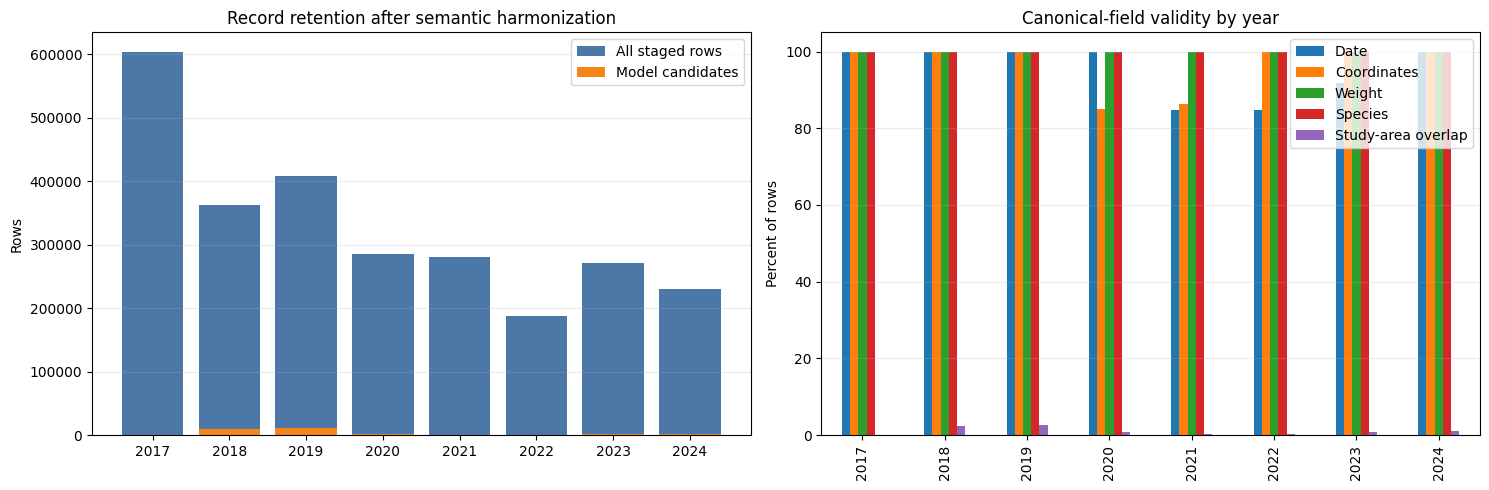

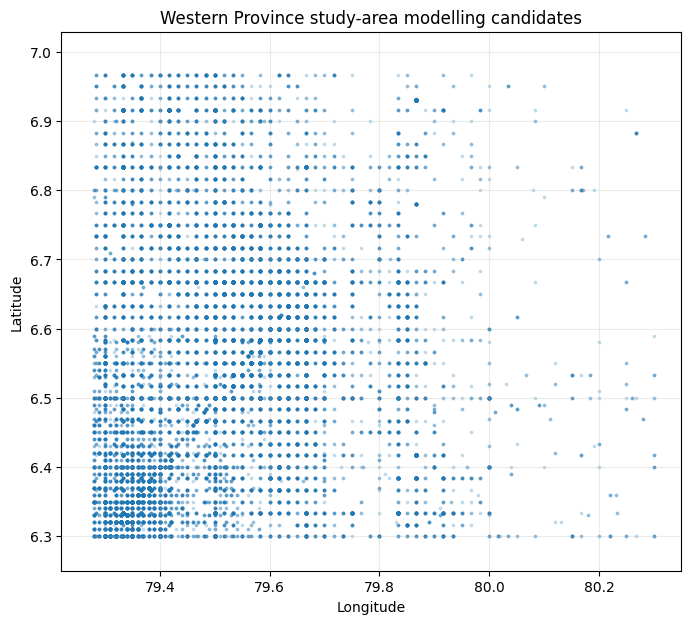

In [15]:
plot=summary.groupby('source_year_label',as_index=False).sum(numeric_only=True)
fig,axes=plt.subplots(1,2,figsize=(15,5))
axes[0].bar(plot.source_year_label.astype(str),plot.rows,label='All staged rows',color='#4c78a8')
axes[0].bar(plot.source_year_label.astype(str),plot.model_candidates,label='Model candidates',color='#f58518')
axes[0].set_title('Record retention after semantic harmonization'); axes[0].set_ylabel('Rows'); axes[0].legend(); axes[0].grid(axis='y',alpha=.25)
validity=pd.DataFrame({'Date':(100*plot.valid_dates/plot.rows).to_numpy(),'Coordinates':(100*plot.valid_coordinates/plot.rows).to_numpy(),
    'Weight':(100*plot.valid_weights/plot.rows).to_numpy(),'Species':(100*plot.valid_species/plot.rows).to_numpy(),
    'Study-area overlap':(100*plot.study_area_rows/plot.rows).to_numpy()},index=plot.source_year_label.astype(str).to_numpy())
validity.plot(kind='bar',ax=axes[1]); axes[1].set_title('Canonical-field validity by year'); axes[1].set_ylabel('Percent of rows'); axes[1].set_ylim(0,105); axes[1].grid(axis='y',alpha=.25)
fig.tight_layout(); path=FIGURE_DIR/'harmonization_summary.png'; fig.savefig(path,dpi=200,bbox_inches='tight'); plt.show()
sample=model_candidates.dropna(subset=['longitude','latitude']).sample(min(50000,len(model_candidates)),random_state=42)
fig,ax=plt.subplots(figsize=(8,7)); ax.scatter(sample.longitude,sample.latitude,s=3,alpha=.2)
ax.set_title('Western Province study-area modelling candidates'); ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.grid(alpha=.25)
ax.set_xlim(STUDY_BOUNDS['longitude_min']-.05,STUDY_BOUNDS['longitude_max']+.05); ax.set_ylim(STUDY_BOUNDS['latitude_min']-.05,STUDY_BOUNDS['latitude_max']+.05)
path2=FIGURE_DIR/'harmonized_spatial_coverage.png'; fig.savefig(path2,dpi=200,bbox_inches='tight'); plt.show()


## 7. Save artifacts and decision evidence

In [16]:
all_path=PROCESSED_DIR/'fisheries_harmonized_all.parquet'; model_path=PROCESSED_DIR/'fisheries_harmonized_model_candidates.parquet'
all_records.to_parquet(all_path,index=False); model_candidates.to_parquet(model_path,index=False)
summary.to_csv(EVIDENCE_DIR/'harmonization_summary.csv',index=False); source_summary.to_csv(EVIDENCE_DIR/'source_mapping_summary.csv',index=False)
pd.DataFrame(MAPPINGS).to_csv(EVIDENCE_DIR/'semantic_mapping.csv',index=False)
manifest={'created_utc':pd.Timestamp.now(tz='UTC').isoformat(),'runtime':'Google Colab' if IN_COLAB else 'Local Windows',
 'study_bounds':STUDY_BOUNDS,
 'assumptions':['weight fields treated as kilograms','rows treated as species catch lines','year-specific fishing dates preferred',
 'coordinate fields follow their source latitude/longitude labels','ambiguous encoded numeric coordinates are flagged but not decoded',
 'model candidates restricted to a provisional Western Province coastal rectangle within the environmental-grid intersection','2022 issue sheet excluded from model candidates',
 'exact canonical duplicates excluded from model candidates','catch weight used instead of CPUE'],
 'all_records':len(all_records),'model_candidates':len(model_candidates),
 'outputs':[str(all_path.name),str(model_path.name)]}
with (EVIDENCE_DIR/'harmonization_manifest.json').open('w',encoding='utf-8') as f: json.dump(manifest,f,indent=2)
print('Saved processed artifacts:',all_path,model_path,sep='\n')


Saved processed artifacts:
/content/drive/MyDrive/FishGuard-C3/data/processed/fisheries_harmonized_all.parquet
/content/drive/MyDrive/FishGuard-C3/data/processed/fisheries_harmonized_model_candidates.parquet


## 8. Next gate

Review retention, validity, date coverage, study-area overlap, and the spatial plot. `03_data_integration.ipynb` can then align daily chlorophyll-a/SST values for the already restricted Western Province modelling candidates. The integration notebook must retain the harmonization flags and report environmental matching success.